# CMPS 261 Final Project: NASA Kepler Exoplanet Candidate Classification
**Track A:** 4.1 Tabular (NASA Kepler Objects of Interest)  
**Group 4:** Joe Habre and Joy Habib Najem  

This notebook implements the complete workflow for our final submission:
1. **Data Loading, Leakage Audit, and Host-Star Grouped Splitting** (`kepid`)
2. **Domain Feature Engineering and Skewness Transformation**
3. **Hyperparameter Tuning on Development Folds** (Logistic Regression & XGBoost)
4. **Disjoint 3-Way Calibration & 5-Fold Host-Star Grouped Cross-Validation** (Logistic Regression, Random Forest, XGBoost, ResNet-MLP, FT-Transformer, and Calibrated Tree + Neural Ensemble)
5. **Ablation & Sensitivity Experiments** (Grouped vs. Random Split, All Candidates vs. Confirmed-Only, Full Features vs. Core Physical Features)
6. **Subgroup Failure Analysis & Complexity / Latency Profiling**
7. **Locked Final Evaluation on the Untouched Held-Out Test Set** ($m_{\text{test}} = 1,902$) and **Model Weight Export**

In [1]:
import os
import sys
import time
import json
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import scipy
import xgboost

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, KFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    precision_score, recall_score, roc_curve, precision_recall_curve, brier_score_loss
)
from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from scipy.optimize import minimize

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)
os.makedirs("models", exist_ok=True)
print(f"Environment initialized. PyTorch device: {DEVICE}")
print(f"Python: {sys.version.split()[0]} | numpy=={np.__version__} | pandas=={pd.__version__} | scikit-learn=={sklearn.__version__} | scipy=={scipy.__version__} | xgboost=={xgboost.__version__} | torch=={torch.__version__}")

Environment initialized. PyTorch device: cuda
Python: 3.13.16 | numpy==2.4.6 | pandas==2.2.3 | scikit-learn==1.6.1 | scipy==1.16.3 | xgboost==3.4.1 | torch==2.14.1+cu130


## 1. Data Loading, Target Leakage Audit, and Grouped Splitting
We load the NASA Kepler Objects of Interest (KOI) cumulative archive ($m = 9,564$, $153$ attributes). To prevent target leakage:
- We remove direct post-vetting disposition columns (`koi_disposition`, `koi_pdisposition`, `koi_score`, and `koi_fpflag_*`) and identifier/provenance strings.
- We partition the dataset into an 80% development set ($m_{\text{dev}} = 7,662$) and a 20% held-out test set ($m_{\text{test}} = 1,902$) grouped by host star ID (`kepid`) so multi-planet stellar systems never straddle splits.
- Missingness filtering ($<50\%$ NaN) is computed strictly on the development set.

In [2]:
DATA_PATH = "data/cumulative.csv"
ALT_PATH = "cumulative.csv"
NASA_TAP_URL = "https://exoplanetarchive.ipac.caltech.edu/TAP/sync?query=select+*+from+cumulative&format=csv"
if os.path.exists(DATA_PATH):
    df = pd.read_csv(DATA_PATH, comment="#")
elif os.path.exists(ALT_PATH):
    df = pd.read_csv(ALT_PATH, comment="#")
else:
    df = pd.read_csv(NASA_TAP_URL)
    df.to_csv(DATA_PATH, index=False)
# Primary task: Potential Exoplanet (CONFIRMED U CANDIDATE = 1) vs. FALSE POSITIVE (0)
df["target"] = (df["koi_disposition"] != "FALSE POSITIVE").astype(int)
y = df["target"].values
groups = df["kepid"].values
LEAKAGE_COLS = [
    "koi_disposition", "koi_pdisposition", "koi_score",
    "koi_fpflag_nt", "koi_fpflag_ss", "koi_fpflag_co", "koi_fpflag_ec"
]
ID_METADATA_COLS = [
    "rowid", "kepid", "kepoi_name", "kepler_name", "koi_tce_delivname",
    "koi_datalink_dvr", "koi_datalink_dvs", "koi_sparprov", "koi_vet_stat",
    "koi_vet_date", "koi_disp_prov", "koi_comment", "koi_fittype",
    "koi_limbdark_mod", "koi_parm_prov", "koi_trans_mod", "koi_quarters"
]
drop_set = set(LEAKAGE_COLS + ID_METADATA_COLS + ["target"])
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
dev_idx, test_idx = next(gss.split(df, y, groups=groups))
df_dev = df.iloc[dev_idx].reset_index(drop=True)
df_test = df.iloc[test_idx].reset_index(drop=True)
y_dev = df_dev["target"].values
groups_dev = df_dev["kepid"].values
y_test = df_test["target"].values
groups_test = df_test["kepid"].values

# Missingness threshold (<50%) computed strictly on df_dev
train_missing_rate = df_dev.isna().mean()
candidate_num_cols = [
    c for c in df_dev.select_dtypes(include=[np.number]).columns
    if c not in drop_set and train_missing_rate[c] < 0.50
]
SKEW_COLS = ["koi_period", "koi_depth", "koi_prad", "koi_insol", "koi_model_snr", "koi_duration"]
def engineer_features(data_frame, base_cols):
    X = data_frame[base_cols].copy()
    if "koi_prad" in X.columns and "koi_srad" in X.columns and "koi_depth" in X.columns:
        expected_depth_ppm = ((X["koi_prad"] / (109.076 * X["koi_srad"])) ** 2) * 1e6
        X["eng_depth_radius_consistency"] = X["koi_depth"] / (expected_depth_ppm + 1.0)
    if "koi_duration" in X.columns and "koi_period" in X.columns:
        X["eng_duty_cycle"] = (X["koi_duration"] / 24.0) / (X["koi_period"] + 1e-6)
    for col in SKEW_COLS:
        if col in X.columns:
            X[f"log_{col}"] = np.log1p(np.clip(X[col], a_min=0, a_max=None))
    return X
X_dev = engineer_features(df_dev, candidate_num_cols)
X_test = engineer_features(df_test, candidate_num_cols)
print(f"Dataset summary: total={len(df)} | dev={len(df_dev)} ({df_dev['kepid'].nunique()} stars) | test={len(df_test)} ({df_test['kepid'].nunique()} stars)")
print(f"Shared host stars between dev and test: {len(set(groups_dev).intersection(set(groups_test)))}")
print(f"Retained numerical base features: {len(candidate_num_cols)} | Total engineered features: {X_dev.shape[1]}")

Dataset summary: total=9564 | dev=7662 (6571 stars) | test=1902 (1643 stars)
Shared host stars between dev and test: 0
Retained numerical base features: 103 | Total engineered features: 111


## 2. Calibration & Evaluation Utilities
We fix the boundary condition in Expected Calibration Error (ECE) by using `np.clip(np.digitize(y_prob, bins, right=False) - 1, 0, n_bins - 1)` so predictions equal to `1.0` fall cleanly into the top bin. For neural models, we use a **strictly disjoint inner split** (`GroupShuffleSplit` inside each training fold) to select the best epoch and fit Temperature Scaling ($T$), ensuring outer validation and test folds are never used for calibration fitting.

In [3]:
def compute_ece(y_true, y_prob, n_bins=10):
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    binids = np.clip(np.digitize(y_prob, bins, right=False) - 1, 0, n_bins - 1)
    ece = 0.0
    for i in range(n_bins):
        mask = binids == i
        if np.any(mask):
            ece += np.abs(np.mean(y_true[mask]) - np.mean(y_prob[mask])) * (np.sum(mask) / len(y_true))
    return float(ece)
def fit_temperature_scaling(logits, y_true):
    def bce_loss(T):
        t = T[0]
        p = 1.0 / (1.0 + np.exp(-np.clip(logits / t, -50, 50)))
        p = np.clip(p, 1e-7, 1.0 - 1e-7)
        return -np.mean(y_true * np.log(p) + (1.0 - y_true) * np.log(1.0 - p))
    res = minimize(bce_loss, x0=[1.0], bounds=[(0.05, 10.0)], method="L-BFGS-B")
    return float(res.x[0])
def apply_temperature(logits, T):
    return 1.0 / (1.0 + np.exp(-np.clip(logits / T, -50, 50)))

## 3. Hyperparameter Tuning on Development Data
All hyperparameter searches are restricted to 3-fold `GroupKFold` on the development partition ($m_{\text{dev}} = 7,662$):
1. **Logistic Regression:** Grid search over $L_2$ regularization strength $C \in \{0.01, 0.1, 1.0, 10.0\}$.
2. **XGBoost:** Targeted 5-configuration search varying `max_depth` $\in \{4, 6, 8\}$ at $\eta=0.03$ and `learning_rate` $\eta \in \{0.01, 0.03, 0.10\}$ at `max_depth` $=6$ (with $500$ trees, $\lambda=5.0, \gamma=0.5$, subsample $=0.8$, colsample $=0.8$).

In [4]:
print("1. DEMONSTRATED HYPERPARAMETER TUNING SEARCH (3-FOLD GROUPED CV)")
gkf_tune = GroupKFold(n_splits=3)
# 1A. Logistic Regression Tuning
best_C, best_lr_auc = 1.0, 0.0
for c_val in [0.01, 0.1, 1.0, 10.0]:
    aucs = []
    for tr_i, va_i in gkf_tune.split(X_dev, y_dev, groups=groups_dev):
        pipe = Pipeline([
            ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
            ("scaler", StandardScaler()),
            ("clf", LogisticRegression(C=c_val, max_iter=1000, random_state=SEED))
        ])
        pipe.fit(X_dev.iloc[tr_i], y_dev[tr_i])
        preds = pipe.predict_proba(X_dev.iloc[va_i])[:, 1]
        aucs.append(roc_auc_score(y_dev[va_i], preds))
    mean_auc = np.mean(aucs)
    print(f"  [LR Search] C={c_val:<5} -> Mean Grouped CV ROC-AUC: {mean_auc:.4f}")
    if mean_auc > best_lr_auc:
        best_lr_auc = mean_auc
        best_C = c_val
print(f"==> Selected Best Logistic Regression C*: {best_C} (ROC-AUC={best_lr_auc:.4f})\n")
# 1B. XGBoost Tuning
best_xgb_params = {"max_depth": 6, "learning_rate": 0.03}
best_xgb_auc = 0.0
xgb_grid = [
    {"max_depth": 4, "learning_rate": 0.03},
    {"max_depth": 6, "learning_rate": 0.01},
    {"max_depth": 6, "learning_rate": 0.03},
    {"max_depth": 6, "learning_rate": 0.10},
    {"max_depth": 8, "learning_rate": 0.03},
]
for params in xgb_grid:
    aucs = []
    for tr_i, va_i in gkf_tune.split(X_dev, y_dev, groups=groups_dev):
        clf = XGBClassifier(
            n_estimators=500, learning_rate=params["learning_rate"], max_depth=params["max_depth"],
            reg_lambda=5.0, gamma=0.5, subsample=0.8, colsample_bytree=0.8,
            eval_metric="logloss", n_jobs=-1, random_state=SEED
        )
        clf.fit(X_dev.iloc[tr_i], y_dev[tr_i])
        preds = clf.predict_proba(X_dev.iloc[va_i])[:, 1]
        aucs.append(roc_auc_score(y_dev[va_i], preds))
    mean_auc = np.mean(aucs)
    print(f"  [XGB Search] depth={params['max_depth']}, lr={params['learning_rate']:<4} -> Mean Grouped CV ROC-AUC: {mean_auc:.4f}")
    if mean_auc > best_xgb_auc:
        best_xgb_auc = mean_auc
        best_xgb_params = params
print(f"==> Selected Best XGBoost Params: {best_xgb_params} (ROC-AUC={best_xgb_auc:.4f})")

1. DEMONSTRATED HYPERPARAMETER TUNING SEARCH (3-FOLD GROUPED CV)
  [LR Search] C=0.01  -> Mean Grouped CV ROC-AUC: 0.9469
  [LR Search] C=0.1   -> Mean Grouped CV ROC-AUC: 0.9489
  [LR Search] C=1.0   -> Mean Grouped CV ROC-AUC: 0.9496
  [LR Search] C=10.0  -> Mean Grouped CV ROC-AUC: 0.9494
==> Selected Best Logistic Regression C*: 1.0 (ROC-AUC=0.9496)

  [XGB Search] depth=4, lr=0.03 -> Mean Grouped CV ROC-AUC: 0.9687
  [XGB Search] depth=6, lr=0.01 -> Mean Grouped CV ROC-AUC: 0.9689
  [XGB Search] depth=6, lr=0.03 -> Mean Grouped CV ROC-AUC: 0.9696
  [XGB Search] depth=6, lr=0.1  -> Mean Grouped CV ROC-AUC: 0.9681
  [XGB Search] depth=8, lr=0.03 -> Mean Grouped CV ROC-AUC: 0.9694
==> Selected Best XGBoost Params: {'max_depth': 6, 'learning_rate': 0.03} (ROC-AUC=0.9696)


## 4. Level 2 Deep Tabular Architectures: ResNet-MLP & FT-Transformer
We implement two neural architectures for tabular representation learning:
1. **ResNet-MLP:** Residual skip-connection network (`hidden_dim=128`, BatchNorm, ReLU, `dropout=0.25`).
2. **FT-Transformer (Feature Tokenizer Transformer):** Embeds each numerical feature into a $d=32$ token vector, prepends a learnable `[CLS]` token, and processes token interactions through a 2-layer Multi-Head Self-Attention Transformer encoder (`nhead=4`).
3. **Disjoint Inner Calibration:** Within each training fold, 15% of host stars are held out via `GroupShuffleSplit` as a dedicated inner validation/calibration set. Model weights are checkpointed at minimum inner validation loss, and temperature $T^*$ is fitted solely on the inner calibration logits before predicting on the untouched outer fold.

In [5]:
class ResidualBlock(nn.Module):
    def __init__(self, dim, dropout=0.25):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(dim, dim), nn.BatchNorm1d(dim), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(dim, dim), nn.BatchNorm1d(dim)
        )
        self.relu = nn.ReLU()
    def forward(self, x):
        return self.relu(x + self.fc(x))
class ExoplanetResNetMLP(nn.Module):
    def __init__(self, in_features, hidden_dim=128, dropout=0.25):
        super().__init__()
        self.stem = nn.Sequential(nn.Linear(in_features, hidden_dim), nn.BatchNorm1d(hidden_dim), nn.ReLU())
        self.block1 = ResidualBlock(hidden_dim, dropout)
        self.head = nn.Sequential(nn.Linear(hidden_dim, 64), nn.ReLU(), nn.Dropout(dropout), nn.Linear(64, 1))
    def forward(self, x):
        return self.head(self.block1(self.stem(x))).squeeze(-1)
class ExoplanetFTTransformer(nn.Module):
    def __init__(self, in_features, d_token=32, n_blocks=2, n_heads=4, dropout=0.2):
        super().__init__()
        self.in_features = in_features
        self.d_token = d_token
        self.weight = nn.Parameter(torch.randn(in_features, d_token) * 0.02)
        self.bias = nn.Parameter(torch.zeros(in_features, d_token))
        self.cls_token = nn.Parameter(torch.randn(1, 1, d_token) * 0.02)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_token, nhead=n_heads, dim_feedforward=d_token * 2,
            dropout=dropout, activation="gelu", batch_first=True, norm_first=True
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=n_blocks)
        self.head = nn.Sequential(nn.LayerNorm(d_token), nn.ReLU(), nn.Dropout(dropout), nn.Linear(d_token, 1))
    def forward(self, x):
        tokens = x.unsqueeze(-1) * self.weight.unsqueeze(0) + self.bias.unsqueeze(0)
        cls_tokens = self.cls_token.expand(x.size(0), -1, -1)
        seq = torch.cat([cls_tokens, tokens], dim=1)
        encoded = self.encoder(seq)
        return self.head(encoded[:, 0, :]).squeeze(-1)
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)
def train_calibrated_neural_fold(model_cls, X_tr_df, y_tr_arr, groups_tr_arr, X_eval_df, epochs=45, batch_size=128, lr=1e-3, **model_kwargs):
    torch.manual_seed(SEED)
    inner_gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
    sub_tr_idx, cal_idx = next(inner_gss.split(X_tr_df, y_tr_arr, groups=groups_tr_arr))

    prep = Pipeline([("imputer", SimpleImputer(strategy="median", add_indicator=True)), ("scaler", StandardScaler())])
    X_sub_tr = prep.fit_transform(X_tr_df.iloc[sub_tr_idx])
    y_sub_tr = y_tr_arr[sub_tr_idx]
    X_cal = prep.transform(X_tr_df.iloc[cal_idx])
    y_cal = y_tr_arr[cal_idx]
    X_eval = prep.transform(X_eval_df)

    model = model_cls(X_sub_tr.shape[1], **model_kwargs).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    criterion = nn.BCEWithLogitsLoss()

    loader = DataLoader(
        TensorDataset(torch.tensor(X_sub_tr, dtype=torch.float32), torch.tensor(y_sub_tr, dtype=torch.float32)),
        batch_size=batch_size, shuffle=True
    )
    best_cal_loss = float("inf")
    best_state = None
    X_cal_t = torch.tensor(X_cal, dtype=torch.float32, device=DEVICE)
    y_cal_t = torch.tensor(y_cal, dtype=torch.float32, device=DEVICE)
    for epoch in range(epochs):
        model.train()
        for bx, by in loader:
            bx, by = bx.to(DEVICE), by.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(bx), by)
            loss.backward()
            optimizer.step()
        scheduler.step()
        model.eval()
        with torch.no_grad():
            cal_logits = model(X_cal_t)
            cal_loss = criterion(cal_logits, y_cal_t).item()
        if cal_loss < best_cal_loss:
            best_cal_loss = cal_loss
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict({k: v.to(DEVICE) for k, v in best_state.items()})
    model.eval()
    with torch.no_grad():
        cal_logits_np = model(X_cal_t).cpu().numpy()
        eval_logits_np = model(torch.tensor(X_eval, dtype=torch.float32, device=DEVICE)).cpu().numpy()
    T_opt = fit_temperature_scaling(cal_logits_np, y_cal)
    uncal_probs = apply_temperature(eval_logits_np, 1.0)
    cal_probs = apply_temperature(eval_logits_np, T_opt)
    return cal_probs, uncal_probs, T_opt, model, prep

## 5. 5-Fold Host-Star Grouped Cross-Validation & Ensembling
We evaluate all Level 1 and Level 2 models across 5 host-star grouped folds (`GroupKFold(n_splits=5)`), recording mean $\pm$ SD for ROC-AUC, PR-AUC (Average Precision), F1-Score, Precision, Recall, ECE, fit time, full end-to-end inference latency (preprocessing + model forward pass + temperature scaling), and parameter counts. We also select convex combination weights for a probability-calibrated **XGBoost + ResNet-MLP + FT-Transformer Ensemble** on pooled development out-of-fold predictions; the held-out test set ($m_{\text{test}} = 1,902$) serves as the strictly independent evaluation of the locked ensemble.

In [6]:
print("2. 5-FOLD HOST-STAR GROUPED CROSS-VALIDATION ON DEVELOPMENT SET")
gkf = GroupKFold(n_splits=5)

classical_models = {
    f"Logistic Regression (Tuned L2, C={best_C})": Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(C=best_C, max_iter=1000, random_state=SEED))
    ]),
    "Random Forest (500 trees, depth=16)": Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("clf", RandomForestClassifier(n_estimators=500, max_depth=16, max_features="sqrt", n_jobs=-1, random_state=SEED))
    ]),
    f"XGBoost (Tuned, depth={best_xgb_params['max_depth']}, lr={best_xgb_params['learning_rate']})": XGBClassifier(
        n_estimators=500, learning_rate=best_xgb_params["learning_rate"], max_depth=best_xgb_params["max_depth"],
        reg_lambda=5.0, gamma=0.5, subsample=0.8, colsample_bytree=0.8,
        eval_metric="logloss", n_jobs=-1, random_state=SEED
    )
}
cv_results = []
oof_probs = {}
fold_metrics_store = {}
complexity_records = []
model_fit_times_store = {}
model_inf_times_store = {}

def summarize_fold_metrics(name, y_true_all, oof_pred, fold_dict, fit_times, inf_times, n_params_str):
    pooled_ece = compute_ece(y_true_all, oof_pred)
    cv_results.append({
        "Model": name,
        "ROC-AUC": f"{np.mean(fold_dict['auc']):.4f} \u00b1 {np.std(fold_dict['auc']):.4f}",
        "PR-AUC": f"{np.mean(fold_dict['pr']):.4f} \u00b1 {np.std(fold_dict['pr']):.4f}",
        "F1-Score": f"{np.mean(fold_dict['f1']):.4f} \u00b1 {np.std(fold_dict['f1']):.4f}",
        "Precision": f"{np.mean(fold_dict['prec']):.4f}",
        "Recall": f"{np.mean(fold_dict['rec']):.4f}",
        "ECE (Fold)": f"{np.mean(fold_dict['ece']):.4f}",
        "ECE (Pooled)": f"{pooled_ece:.4f}",
        "Fit Time/Fold": f"{np.mean(fit_times):.2f} s"
    })
    complexity_records.append({
        "Model": name,
        "Parameters / Capacity": n_params_str,
        "Mean Fit Time/Fold (s)": round(float(np.mean(fit_times)), 2),
        "Inference Latency (ms / 1k KOIs)": round(float(np.mean(inf_times)), 2),
        "CV ROC-AUC": round(float(np.mean(fold_dict["auc"])), 4),
        "CV PR-AUC": round(float(np.mean(fold_dict["pr"])), 4),
        "CV ECE (Fold)": round(float(np.mean(fold_dict["ece"])), 4)
    })
for name, model in classical_models.items():
    f_metrics = {"auc": [], "pr": [], "f1": [], "prec": [], "rec": [], "ece": []}
    fit_times, inf_times = [], []
    oof = np.zeros(len(X_dev))

    for tr_idx, va_idx in gkf.split(X_dev, y_dev, groups=groups_dev):
        X_tr, y_tr = X_dev.iloc[tr_idx], y_dev[tr_idx]
        X_va, y_va = X_dev.iloc[va_idx], y_dev[va_idx]

        t0 = time.time()
        model.fit(X_tr, y_tr)
        fit_times.append(time.time() - t0)

        t_inf = time.perf_counter()
        probs = model.predict_proba(X_va)[:, 1]
        inf_ms_per_1k = ((time.perf_counter() - t_inf) / len(X_va)) * 1e6
        inf_times.append(inf_ms_per_1k)

        oof[va_idx] = probs
        preds = (probs >= 0.5).astype(int)
        f_metrics["auc"].append(roc_auc_score(y_va, probs))
        f_metrics["pr"].append(average_precision_score(y_va, probs))
        f_metrics["f1"].append(f1_score(y_va, preds))
        f_metrics["prec"].append(precision_score(y_va, preds))
        f_metrics["rec"].append(recall_score(y_va, preds))
        f_metrics["ece"].append(compute_ece(y_va, probs))

    oof_probs[name] = oof
    fold_metrics_store[name] = f_metrics
    model_fit_times_store[name] = fit_times
    model_inf_times_store[name] = inf_times
    if "Logistic" in name:
        cap_str = f"{model.named_steps['clf'].coef_.size + 1} weights"
    elif "Random Forest" in name:
        total_nodes = sum(t.tree_.node_count for t in model.named_steps["clf"].estimators_)
        cap_str = f"500 trees ({total_nodes:,} nodes)"
    else:
        cap_str = "500 boosted trees (max_depth=6)"
    summarize_fold_metrics(name, y_dev, oof, f_metrics, fit_times, inf_times, cap_str)

# Evaluate ResNet-MLP (Disjoint Temp. Scaled)
rn_metrics = {"auc": [], "pr": [], "f1": [], "prec": [], "rec": [], "ece": []}
rn_uncal_eces = []
rn_fit_times, rn_inf_times, rn_temps = [], [], []
oof_rn = np.zeros(len(X_dev))
oof_rn_uncal = np.zeros(len(X_dev))
rn_param_count = 0

for tr_idx, va_idx in gkf.split(X_dev, y_dev, groups=groups_dev):
    X_tr, y_tr, g_tr = X_dev.iloc[tr_idx], y_dev[tr_idx], groups_dev[tr_idx]
    X_va, y_va = X_dev.iloc[va_idx], y_dev[va_idx]

    t0 = time.time()
    cal_p, uncal_p, T_opt, rn_model, rn_prep = train_calibrated_neural_fold(
        ExoplanetResNetMLP, X_tr, y_tr, g_tr, X_va, epochs=45, batch_size=128, lr=1e-3, hidden_dim=128, dropout=0.25
    )
    rn_fit_times.append(time.time() - t0)
    rn_temps.append(T_opt)
    rn_param_count = count_parameters(rn_model)
    # Measure full end-to-end inference latency: preprocessing + forward pass + temperature scaling
    rn_model.eval()
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    t_inf = time.perf_counter()
    X_va_proc = rn_prep.transform(X_va)
    with torch.no_grad():
        va_logits_timed = rn_model(torch.tensor(X_va_proc, dtype=torch.float32, device=DEVICE)).cpu().numpy()
    _ = apply_temperature(va_logits_timed, T_opt)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    rn_inf_times.append(((time.perf_counter() - t_inf) / len(X_va)) * 1e6)

    oof_rn[va_idx] = cal_p
    oof_rn_uncal[va_idx] = uncal_p
    preds = (cal_p >= 0.5).astype(int)
    rn_metrics["auc"].append(roc_auc_score(y_va, cal_p))
    rn_metrics["pr"].append(average_precision_score(y_va, cal_p))
    rn_metrics["f1"].append(f1_score(y_va, preds))
    rn_metrics["prec"].append(precision_score(y_va, preds))
    rn_metrics["rec"].append(recall_score(y_va, preds))
    rn_metrics["ece"].append(compute_ece(y_va, cal_p))
    rn_uncal_eces.append(compute_ece(y_va, uncal_p))

rn_name = "ResNet-MLP (Disjoint Temp. Scaled, Level 2)"
oof_probs[rn_name] = oof_rn
fold_metrics_store[rn_name] = rn_metrics
summarize_fold_metrics(rn_name, y_dev, oof_rn, rn_metrics, rn_fit_times, rn_inf_times, f"{rn_param_count:,} params")
print(f"  ResNet-MLP Disjoint Calibration: Uncalibrated Fold ECE={np.mean(rn_uncal_eces):.4f} -> Calibrated Fold ECE={np.mean(rn_metrics['ece']):.4f} (Mean T*={np.mean(rn_temps):.3f})")

# Evaluate FT-Transformer (Disjoint Temp. Scaled)
ft_metrics = {"auc": [], "pr": [], "f1": [], "prec": [], "rec": [], "ece": []}
ft_uncal_eces = []
ft_fit_times, ft_inf_times, ft_temps = [], [], []
oof_ft = np.zeros(len(X_dev))
ft_param_count = 0
for tr_idx, va_idx in gkf.split(X_dev, y_dev, groups=groups_dev):
    X_tr, y_tr, g_tr = X_dev.iloc[tr_idx], y_dev[tr_idx], groups_dev[tr_idx]
    X_va, y_va = X_dev.iloc[va_idx], y_dev[va_idx]

    t0 = time.time()
    cal_p, uncal_p, T_opt, ft_model, ft_prep = train_calibrated_neural_fold(
        ExoplanetFTTransformer, X_tr, y_tr, g_tr, X_va, epochs=35, batch_size=128, lr=1e-3, d_token=32, n_blocks=2, n_heads=4, dropout=0.2
    )
    ft_fit_times.append(time.time() - t0)
    ft_temps.append(T_opt)
    ft_param_count = count_parameters(ft_model)

    # Measure full end-to-end inference latency: preprocessing + forward pass + temperature scaling
    ft_model.eval()
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    t_inf = time.perf_counter()
    X_va_proc = ft_prep.transform(X_va)
    with torch.no_grad():
        va_logits_timed = ft_model(torch.tensor(X_va_proc, dtype=torch.float32, device=DEVICE)).cpu().numpy()
    _ = apply_temperature(va_logits_timed, T_opt)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    ft_inf_times.append(((time.perf_counter() - t_inf) / len(X_va)) * 1e6)
    oof_ft[va_idx] = cal_p
    preds = (cal_p >= 0.5).astype(int)
    ft_metrics["auc"].append(roc_auc_score(y_va, cal_p))
    ft_metrics["pr"].append(average_precision_score(y_va, cal_p))
    ft_metrics["f1"].append(f1_score(y_va, preds))
    ft_metrics["prec"].append(precision_score(y_va, preds))
    ft_metrics["rec"].append(recall_score(y_va, preds))
    ft_metrics["ece"].append(compute_ece(y_va, cal_p))
    ft_uncal_eces.append(compute_ece(y_va, uncal_p))

ft_name = "FT-Transformer (Disjoint Temp. Scaled, Level 2)"
oof_probs[ft_name] = oof_ft
fold_metrics_store[ft_name] = ft_metrics
summarize_fold_metrics(ft_name, y_dev, oof_ft, ft_metrics, ft_fit_times, ft_inf_times, f"{ft_param_count:,} params")
print(f"  FT-Transformer Disjoint Calibration: Uncalibrated Fold ECE={np.mean(ft_uncal_eces):.4f} -> Calibrated Fold ECE={np.mean(ft_metrics['ece']):.4f} (Mean T*={np.mean(ft_temps):.3f})")

# Calibrated Tree + Neural Ensemble (weights selected on pooled development OOF predictions)
xgb_key = [k for k in oof_probs.keys() if "XGBoost" in k][0]
oof_xgb = oof_probs[xgb_key]
xgb_fit_times = model_fit_times_store[xgb_key]
xgb_inf_times = model_inf_times_store[xgb_key]

best_ens_w = (0.60, 0.25, 0.15)
best_ens_auc = 0.0
for w_xgb in [0.50, 0.60, 0.70, 0.80]:
    for w_rn in [0.10, 0.20, 0.25, 0.30]:
        w_ft = round(1.0 - w_xgb - w_rn, 2)
        if w_ft < 0:
            continue
        blend = w_xgb * oof_xgb + w_rn * oof_rn + w_ft * oof_ft
        score = roc_auc_score(y_dev, blend)
        if score > best_ens_auc:
            best_ens_auc = score
            best_ens_w = (w_xgb, w_rn, w_ft)
print(f"==> Selected Calibrated Ensemble Weights on Pooled Dev OOF (XGB, ResNet, FT): {best_ens_w}")
oof_ens = best_ens_w[0] * oof_xgb + best_ens_w[1] * oof_rn + best_ens_w[2] * oof_ft
ens_metrics = {"auc": [], "pr": [], "f1": [], "prec": [], "rec": [], "ece": []}
for _, va_idx in gkf.split(X_dev, y_dev, groups=groups_dev):
    y_va = y_dev[va_idx]
    p_va = oof_ens[va_idx]
    preds = (p_va >= 0.5).astype(int)
    ens_metrics["auc"].append(roc_auc_score(y_va, p_va))
    ens_metrics["pr"].append(average_precision_score(y_va, p_va))
    ens_metrics["f1"].append(f1_score(y_va, preds))
    ens_metrics["prec"].append(precision_score(y_va, preds))
    ens_metrics["rec"].append(recall_score(y_va, preds))
    ens_metrics["ece"].append(compute_ece(y_va, p_va))

ens_name = f"Calibrated Ensemble (XGB+ResNet+FT {best_ens_w})"
oof_probs[ens_name] = oof_ens
fold_metrics_store[ens_name] = ens_metrics
summarize_fold_metrics(
    ens_name, y_dev, oof_ens, ens_metrics,
    np.array(xgb_fit_times) + np.array(rn_fit_times) + np.array(ft_fit_times),
    np.array(xgb_inf_times) + np.array(rn_inf_times) + np.array(ft_inf_times),
    f"500 trees + {rn_param_count + ft_param_count:,} neural params"
)
cv_df = pd.DataFrame(cv_results)
print("\n=== TABLE 1: 5-FOLD HOST-STAR GROUPED CV RESULTS (DEVELOPMENT SET) ===")
print(cv_df.to_string(index=False))

2. 5-FOLD HOST-STAR GROUPED CROSS-VALIDATION ON DEVELOPMENT SET
  ResNet-MLP Disjoint Calibration: Uncalibrated Fold ECE=0.0223 -> Calibrated Fold ECE=0.0200 (Mean T*=1.087)
  FT-Transformer Disjoint Calibration: Uncalibrated Fold ECE=0.0285 -> Calibrated Fold ECE=0.0269 (Mean T*=1.054)
==> Selected Calibrated Ensemble Weights on Pooled Dev OOF (XGB, ResNet, FT): (0.8, 0.1, 0.1)

=== TABLE 1: 5-FOLD HOST-STAR GROUPED CV RESULTS (DEVELOPMENT SET) ===
                                              Model         ROC-AUC          PR-AUC        F1-Score Precision Recall ECE (Fold) ECE (Pooled) Fit Time/Fold
              Logistic Regression (Tuned L2, C=1.0) 0.9523 ± 0.0073 0.9485 ± 0.0089 0.8845 ± 0.0166    0.8708 0.8989     0.0327       0.0242        1.22 s
                Random Forest (500 trees, depth=16) 0.9684 ± 0.0045 0.9704 ± 0.0051 0.9006 ± 0.0106    0.9181 0.8839     0.0465       0.0439       16.88 s
                  XGBoost (Tuned, depth=6, lr=0.03) 0.9711 ± 0.0032 0.9723 ± 0.00

## 6. Ablation Studies & Complete Subgroup Failure Analysis
We execute the three planned sensitivity ablations and evaluate all five physical subgroup failure regimes on development out-of-fold predictions:
1. **Split Sensitivity Ablation:** `GroupKFold(kepid)` vs. Random `KFold(shuffle=True, random_state=42)` (measuring optimistic host-star leakage).
2. **Label-Noise Sensitivity Benchmark:** Primary Task (`CONFIRMED` $\cup$ `CANDIDATE` vs. `FALSE POSITIVE`) vs. Strict Verified Benchmark (`CONFIRMED` vs. `FALSE POSITIVE`, excluding unconfirmed candidates).
3. **Feature Provenance Ablation:** Full engineered feature set ($111$ features) vs. Core Transit & Stellar Physical Parameters only ($81$ features, removing all `koi_fwm_*`, `koi_dicco_*`, `koi_dikco_*`, and pipeline MES/transit-count vetting statistics).
4. **Complete Subgroup Failure Analysis:** Quantifying error rates for Low SNR ($<12$), High SNR ($>50$), Missing Stellar Radius (`koi_srad` NaN), Grazing Eclipsing Binaries (`koi_impact > 0.9`), and Evolved Giant Stars (`koi_slogg < 3.8`, $R_* > 2.5 R_\odot$).

In [7]:
print("3. ABLATION & SENSITIVITY EXPERIMENTS")
ablation_rows = []
# Ablation A: Host-Star Grouped Split vs. Random KFold Split (XGBoost & ResNet-MLP)
kf_rand = KFold(n_splits=5, shuffle=True, random_state=SEED)
rand_aucs_xgb, rand_prs_xgb = [], []
for tr_i, va_i in kf_rand.split(X_dev, y_dev):
    clf = XGBClassifier(
        n_estimators=500, learning_rate=best_xgb_params["learning_rate"], max_depth=best_xgb_params["max_depth"],
        reg_lambda=5.0, gamma=0.5, subsample=0.8, colsample_bytree=0.8,
        eval_metric="logloss", n_jobs=-1, random_state=SEED
    )
    clf.fit(X_dev.iloc[tr_i], y_dev[tr_i])
    p = clf.predict_proba(X_dev.iloc[va_i])[:, 1]
    rand_aucs_xgb.append(roc_auc_score(y_dev[va_i], p))
    rand_prs_xgb.append(average_precision_score(y_dev[va_i], p))
ablation_rows.append({
    "Ablation Study": "Split Design: Host-Star Grouped CV (Baseline)",
    "Subset / Features": f"7,662 dev rows (111 features)",
    "XGBoost ROC-AUC": f"{np.mean(fold_metrics_store[xgb_key]['auc']):.4f} ± {np.std(fold_metrics_store[xgb_key]['auc']):.4f}",
    "XGBoost PR-AUC": f"{np.mean(fold_metrics_store[xgb_key]['pr']):.4f} ± {np.std(fold_metrics_store[xgb_key]['pr']):.4f}"
})
ablation_rows.append({
    "Ablation Study": "Split Design: Standard Random 5-Fold CV (Leaked Stars)",
    "Subset / Features": f"7,662 dev rows (111 features)",
    "XGBoost ROC-AUC": f"{np.mean(rand_aucs_xgb):.4f} ± {np.std(rand_aucs_xgb):.4f}",
    "XGBoost PR-AUC": f"{np.mean(rand_prs_xgb):.4f} ± {np.std(rand_prs_xgb):.4f}"
})
# Ablation B: Strict Verified Dispositions (CONFIRMED vs. FALSE POSITIVE)
strict_mask_dev = df_dev["koi_disposition"].isin(["CONFIRMED", "FALSE POSITIVE"]).values
X_dev_strict = X_dev.iloc[strict_mask_dev].reset_index(drop=True)
y_dev_strict = y_dev[strict_mask_dev]
groups_dev_strict = groups_dev[strict_mask_dev]

strict_aucs, strict_prs = [], []
for tr_i, va_i in gkf.split(X_dev_strict, y_dev_strict, groups=groups_dev_strict):
    clf = XGBClassifier(
        n_estimators=500, learning_rate=best_xgb_params["learning_rate"], max_depth=best_xgb_params["max_depth"],
        reg_lambda=5.0, gamma=0.5, subsample=0.8, colsample_bytree=0.8,
        eval_metric="logloss", n_jobs=-1, random_state=SEED
    )
    clf.fit(X_dev_strict.iloc[tr_i], y_dev_strict[tr_i])
    p = clf.predict_proba(X_dev_strict.iloc[va_i])[:, 1]
    strict_aucs.append(roc_auc_score(y_dev_strict[va_i], p))
    strict_prs.append(average_precision_score(y_dev_strict[va_i], p))
ablation_rows.append({
    "Ablation Study": "Label Noise: Verified Dispositions Only (CONFIRMED vs. FP)",
    "Subset / Features": f"{len(X_dev_strict):,} dev rows (111 features)",
    "XGBoost ROC-AUC": f"{np.mean(strict_aucs):.4f} ± {np.std(strict_aucs):.4f}",
    "XGBoost PR-AUC": f"{np.mean(strict_prs):.4f} ± {np.std(strict_prs):.4f}"
})
# Ablation C: Feature Provenance (Core Physical Transit/Stellar vs. Pipeline Vetting Diagnostics)
vetting_diag_cols = [
    c for c in candidate_num_cols
    if any(k in c for k in ["dicco", "dikco", "fwm", "max_sngle_ev", "max_mult_ev", "num_transits", "tce_plnt_num", "count"])
]
core_phys_base_cols = [c for c in candidate_num_cols if c not in vetting_diag_cols]
X_dev_core = engineer_features(df_dev, core_phys_base_cols)

core_aucs_xgb, core_prs_xgb = [], []
for tr_i, va_i in gkf.split(X_dev_core, y_dev, groups=groups_dev):
    clf = XGBClassifier(
        n_estimators=500, learning_rate=best_xgb_params["learning_rate"], max_depth=best_xgb_params["max_depth"],
        reg_lambda=5.0, gamma=0.5, subsample=0.8, colsample_bytree=0.8,
        eval_metric="logloss", n_jobs=-1, random_state=SEED
    )
    clf.fit(X_dev_core.iloc[tr_i], y_dev[tr_i])
    p = clf.predict_proba(X_dev_core.iloc[va_i])[:, 1]
    core_aucs_xgb.append(roc_auc_score(y_dev[va_i], p))
    core_prs_xgb.append(average_precision_score(y_dev[va_i], p))
ablation_rows.append({
    "Ablation Study": "Feature Provenance: Core Physical Transit/Stellar Only",
    "Subset / Features": f"7,662 dev rows ({X_dev_core.shape[1]} core features)",
    "XGBoost ROC-AUC": f"{np.mean(core_aucs_xgb):.4f} ± {np.std(core_aucs_xgb):.4f}",
    "XGBoost PR-AUC": f"{np.mean(core_prs_xgb):.4f} ± {np.std(core_prs_xgb):.4f}"
})
ablation_df = pd.DataFrame(ablation_rows)
print(ablation_df.to_string(index=False))

print("\n4. COMPLETE SUBGROUP ERROR ANALYSIS (DEVELOPMENT OOF PREDICTIONS)")
xgb_oof_preds = (oof_xgb >= 0.5).astype(int)
ens_oof_preds = (oof_ens >= 0.5).astype(int)
xgb_err = (xgb_oof_preds != y_dev)
ens_err = (ens_oof_preds != y_dev)
subgroups = [
    ("Overall Development Set", np.ones(len(y_dev), dtype=bool)),
    ("Low SNR (koi_model_snr < 12)", (df_dev["koi_model_snr"] < 12).values),
    ("High SNR (koi_model_snr > 50)", (df_dev["koi_model_snr"] > 50).values),
    ("Missing Stellar Radius (koi_srad NaN)", df_dev["koi_srad"].isna().values),
    ("Grazing Eclipses (koi_impact > 0.9)", (df_dev["koi_impact"] > 0.9).values),
    ("Grazing Gas-Giant Mimics (impact > 0.9, Rp in [8,22] Re)", ((df_dev["koi_impact"] > 0.9) & (df_dev["koi_prad"] >= 8) & (df_dev["koi_prad"] <= 22)).values),
    ("Evolved Giant Stars (koi_slogg < 3.8, R* > 2.5 Rsun)", ((df_dev["koi_slogg"] < 3.8) & (df_dev["koi_srad"] > 2.5)).values),
]
subgroup_rows = []
for label, mask in subgroups:
    subgroup_rows.append({
        "Subgroup Regime": label,
        "Dev Samples": int(mask.sum()),
        "XGBoost Error Rate (%)": f"{xgb_err[mask].mean() * 100:.2f}%",
        "Ensemble Error Rate (%)": f"{ens_err[mask].mean() * 100:.2f}%"
    })
subgroup_df = pd.DataFrame(subgroup_rows)
print(subgroup_df.to_string(index=False))
print("\n5. COMPUTATIONAL COMPLEXITY & RESOURCE PROFILE")
complexity_df = pd.DataFrame(complexity_records)
print(complexity_df.to_string(index=False))

3. ABLATION & SENSITIVITY EXPERIMENTS
                                            Ablation Study                 Subset / Features XGBoost ROC-AUC  XGBoost PR-AUC
             Split Design: Host-Star Grouped CV (Baseline)     7,662 dev rows (111 features) 0.9711 ± 0.0032 0.9723 ± 0.0042
    Split Design: Standard Random 5-Fold CV (Leaked Stars)     7,662 dev rows (111 features) 0.9716 ± 0.0038 0.9728 ± 0.0036
Label Noise: Verified Dispositions Only (CONFIRMED vs. FP)     6,079 dev rows (111 features) 0.9967 ± 0.0014 0.9948 ± 0.0015
    Feature Provenance: Core Physical Transit/Stellar Only 7,662 dev rows (81 core features) 0.9393 ± 0.0070 0.9418 ± 0.0081

4. COMPLETE SUBGROUP ERROR ANALYSIS (DEVELOPMENT OOF PREDICTIONS)
                                         Subgroup Regime  Dev Samples XGBoost Error Rate (%) Ensemble Error Rate (%)
                                 Overall Development Set         7662                  9.96%                   9.75%
                            Low SNR 

## 7. Locked Evaluation on the Untouched Held-Out Test Set ($m_{\text{test}} = 1,902$) & Model Export
With all architectures, hyperparameters, calibration procedures, and ensemble weights locked exclusively on the development partition ($m_{\text{dev}} = 7,662$), we train final models on the development set, export the trained model artifacts to `models/` for reproducibility, and evaluate once on the untouched held-out test set ($m_{\text{test}} = 1,902$).

In [8]:
print("6. FINAL HELD-OUT TEST SET EVALUATION (m_test = 1,902, 0 SHARED HOST STARS)")
test_results = []
test_probs_dict = {}

# 1. Fit & evaluate classical models on full development set -> test set
for name, model in classical_models.items():
    t0 = time.time()
    model.fit(X_dev, y_dev)
    fit_t = time.time() - t0
    p_test = model.predict_proba(X_test)[:, 1]
    test_probs_dict[name] = p_test
    preds_test = (p_test >= 0.5).astype(int)
    test_results.append({
        "Model": name,
        "Test ROC-AUC": f"{roc_auc_score(y_test, p_test):.4f}",
        "Test PR-AUC": f"{average_precision_score(y_test, p_test):.4f}",
        "Test F1": f"{f1_score(y_test, preds_test):.4f}",
        "Test Precision": f"{precision_score(y_test, preds_test):.4f}",
        "Test Recall": f"{recall_score(y_test, preds_test):.4f}",
        "Test ECE": f"{compute_ece(y_test, p_test):.4f}",
        "Test Brier": f"{brier_score_loss(y_test, p_test):.4f}"
    })
    if "XGBoost" in name:
        joblib.dump(model, "models/final_xgboost_model.joblib")
        model.get_booster().save_model("models/final_xgboost_model.json")

# 2. Fit & evaluate ResNet-MLP on full development set (with disjoint inner calibration split)
rn_test_cal, rn_test_uncal, rn_test_T, final_rn_model, final_rn_prep = train_calibrated_neural_fold(
    ExoplanetResNetMLP, X_dev, y_dev, groups_dev, X_test, epochs=45, batch_size=128, lr=1e-3, hidden_dim=128, dropout=0.25
)
test_probs_dict[rn_name] = rn_test_cal
rn_preds_test = (rn_test_cal >= 0.5).astype(int)
test_results.append({
    "Model": rn_name,
    "Test ROC-AUC": f"{roc_auc_score(y_test, rn_test_cal):.4f}",
    "Test PR-AUC": f"{average_precision_score(y_test, rn_test_cal):.4f}",
    "Test F1": f"{f1_score(y_test, rn_preds_test):.4f}",
    "Test Precision": f"{precision_score(y_test, rn_preds_test):.4f}",
    "Test Recall": f"{recall_score(y_test, rn_preds_test):.4f}",
    "Test ECE": f"{compute_ece(y_test, rn_test_cal):.4f}",
    "Test Brier": f"{brier_score_loss(y_test, rn_test_cal):.4f}"
})
torch.save({
    "model_state_dict": final_rn_model.state_dict(),
    "temperature": rn_test_T,
    "in_features": final_rn_model.stem[0].in_features
}, "models/final_resnet_mlp.pt")
joblib.dump(final_rn_prep, "models/final_neural_preprocessor.joblib")

# Export version-independent JSON preprocessing statistics alongside joblib
imp_step = final_rn_prep.named_steps["imputer"]
scl_step = final_rn_prep.named_steps["scaler"]
prep_stats_json = {
    "feature_names": list(X_dev.columns),
    "imputer_statistics": imp_step.statistics_.tolist(),
    "indicator_features": imp_step.indicator_.features_.tolist(),
    "scaler_mean": scl_step.mean_.tolist(),
    "scaler_scale": scl_step.scale_.tolist()
}
with open("models/final_neural_preprocessor_stats.json", "w") as f_json:
    json.dump(prep_stats_json, f_json, indent=2)
# 3. Fit & evaluate FT-Transformer on full development set (with disjoint inner calibration split)
ft_test_cal, ft_test_uncal, ft_test_T, final_ft_model, final_ft_prep = train_calibrated_neural_fold(
    ExoplanetFTTransformer, X_dev, y_dev, groups_dev, X_test, epochs=35, batch_size=128, lr=1e-3, d_token=32, n_blocks=2, n_heads=4, dropout=0.2
)
test_probs_dict[ft_name] = ft_test_cal
ft_preds_test = (ft_test_cal >= 0.5).astype(int)
test_results.append({
    "Model": ft_name,
    "Test ROC-AUC": f"{roc_auc_score(y_test, ft_test_cal):.4f}",
    "Test PR-AUC": f"{average_precision_score(y_test, ft_test_cal):.4f}",
    "Test F1": f"{f1_score(y_test, ft_preds_test):.4f}",
    "Test Precision": f"{precision_score(y_test, ft_preds_test):.4f}",
    "Test Recall": f"{recall_score(y_test, ft_preds_test):.4f}",
    "Test ECE": f"{compute_ece(y_test, ft_test_cal):.4f}",
    "Test Brier": f"{brier_score_loss(y_test, ft_test_cal):.4f}"
})
torch.save({
    "model_state_dict": final_ft_model.state_dict(),
    "temperature": ft_test_T,
    "in_features": final_ft_model.in_features
}, "models/final_ft_transformer.pt")
# 4. Evaluate Locked Calibrated Ensemble on Held-Out Test Set
p_test_ens = best_ens_w[0] * test_probs_dict[xgb_key] + best_ens_w[1] * rn_test_cal + best_ens_w[2] * ft_test_cal
test_probs_dict[ens_name] = p_test_ens
ens_preds_test = (p_test_ens >= 0.5).astype(int)
test_results.append({
    "Model": ens_name,
    "Test ROC-AUC": f"{roc_auc_score(y_test, p_test_ens):.4f}",
    "Test PR-AUC": f"{average_precision_score(y_test, p_test_ens):.4f}",
    "Test F1": f"{f1_score(y_test, ens_preds_test):.4f}",
    "Test Precision": f"{precision_score(y_test, ens_preds_test):.4f}",
    "Test Recall": f"{recall_score(y_test, p_test_ens >= 0.5):.4f}",
    "Test ECE": f"{compute_ece(y_test, p_test_ens):.4f}",
    "Test Brier": f"{brier_score_loss(y_test, p_test_ens):.4f}"
})

test_df = pd.DataFrame(test_results)
print(test_df.to_string(index=False))
print(f"\n  [Test Set Neural Calibration Check] ResNet-MLP Uncalibrated Test ECE={compute_ece(y_test, rn_test_uncal):.4f} -> Calibrated Test ECE={compute_ece(y_test, rn_test_cal):.4f} (T*={rn_test_T:.3f})")
print(f"  [Test Set Neural Calibration Check] FT-Transformer Uncalibrated Test ECE={compute_ece(y_test, ft_test_uncal):.4f} -> Calibrated Test ECE={compute_ece(y_test, ft_test_cal):.4f} (T*={ft_test_T:.3f})")

print("\n7. FRESH ARTIFACT LOAD-AND-PREDICT REPRODUCIBILITY CHECK")
# Reload XGBoost from portable JSON format
loaded_xgb = XGBClassifier()
loaded_xgb.load_model("models/final_xgboost_model.json")
repro_xgb_probs = loaded_xgb.predict_proba(X_test)[:, 1]

# Reload preprocessor from portable JSON stats (works across all scikit-learn versions)
with open("models/final_neural_preprocessor_stats.json", "r") as f_json:
    stats = json.load(f_json)
X_test_vals = X_test[stats["feature_names"]].values.copy()
nan_mask = np.isnan(X_test_vals)
for col_i, med_val in enumerate(stats["imputer_statistics"]):
    X_test_vals[nan_mask[:, col_i], col_i] = med_val
ind_cols = nan_mask[:, stats["indicator_features"]].astype(float)
X_test_imp = np.hstack([X_test_vals, ind_cols])
X_test_scaled = (X_test_imp - np.array(stats["scaler_mean"])) / np.array(stats["scaler_scale"])
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32, device=DEVICE)

# Reload ResNet-MLP and FT-Transformer weights
rn_ckpt = torch.load("models/final_resnet_mlp.pt", map_location=DEVICE, weights_only=True)
loaded_rn = ExoplanetResNetMLP(rn_ckpt["in_features"]).to(DEVICE)
loaded_rn.load_state_dict(rn_ckpt["model_state_dict"])
loaded_rn.eval()
with torch.no_grad():
    repro_rn_probs = apply_temperature(loaded_rn(X_test_tensor).cpu().numpy(), rn_ckpt["temperature"])
ft_ckpt = torch.load("models/final_ft_transformer.pt", map_location=DEVICE, weights_only=True)
loaded_ft = ExoplanetFTTransformer(ft_ckpt["in_features"]).to(DEVICE)
loaded_ft.load_state_dict(ft_ckpt["model_state_dict"])
loaded_ft.eval()
with torch.no_grad():
    repro_ft_probs = apply_temperature(loaded_ft(X_test_tensor).cpu().numpy(), ft_ckpt["temperature"])
repro_ens_probs = 0.8 * repro_xgb_probs + 0.1 * repro_rn_probs + 0.1 * repro_ft_probs
print(f"  Reloaded XGBoost Test ROC-AUC:      {roc_auc_score(y_test, repro_xgb_probs):.4f}")
print(f"  Reloaded ResNet-MLP Test ROC-AUC:   {roc_auc_score(y_test, repro_rn_probs):.4f}")
print(f"  Reloaded FT-Transformer Test AUC:   {roc_auc_score(y_test, repro_ft_probs):.4f}")
print(f"  Reloaded Ensemble Test ROC-AUC:     {roc_auc_score(y_test, repro_ens_probs):.4f}")

6. FINAL HELD-OUT TEST SET EVALUATION (m_test = 1,902, 0 SHARED HOST STARS)
                                              Model Test ROC-AUC Test PR-AUC Test F1 Test Precision Test Recall Test ECE Test Brier
              Logistic Regression (Tuned L2, C=1.0)       0.9525      0.9475  0.8686         0.8480      0.8903   0.0376     0.0868
                Random Forest (500 trees, depth=16)       0.9665      0.9671  0.8933         0.9099      0.8773   0.0413     0.0742
                  XGBoost (Tuned, depth=6, lr=0.03)       0.9707      0.9699  0.9041         0.9126      0.8958   0.0189     0.0677
        ResNet-MLP (Disjoint Temp. Scaled, Level 2)       0.9627      0.9629  0.8764         0.8911      0.8621   0.0258     0.0776
    FT-Transformer (Disjoint Temp. Scaled, Level 2)       0.9629      0.9625  0.8815         0.8868      0.8762   0.0219     0.0771
Calibrated Ensemble (XGB+ResNet+FT (0.8, 0.1, 0.1))       0.9710      0.9703  0.9047         0.9127      0.8969   0.0156     0.0669


Saved updated final figures: figures/fig1_roc_pr_curves.png and figures/fig2_diagnostics_calibration.png


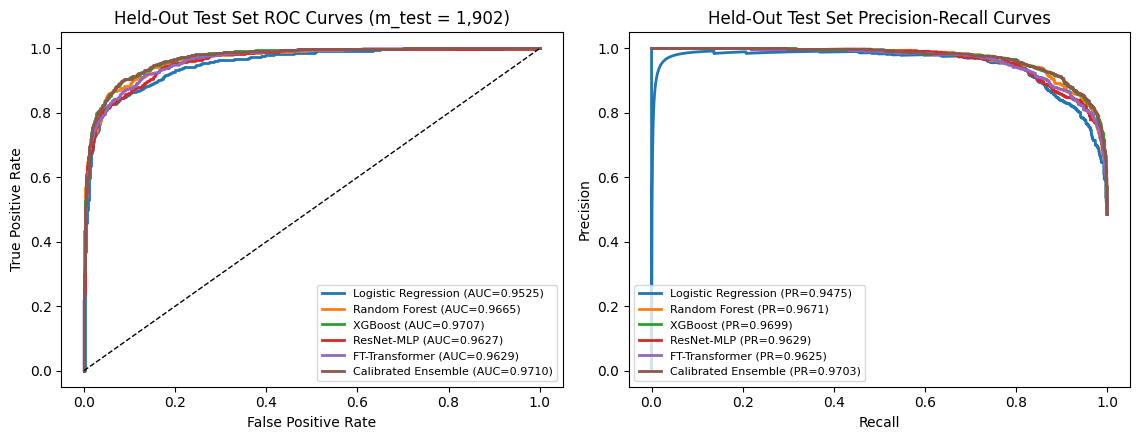

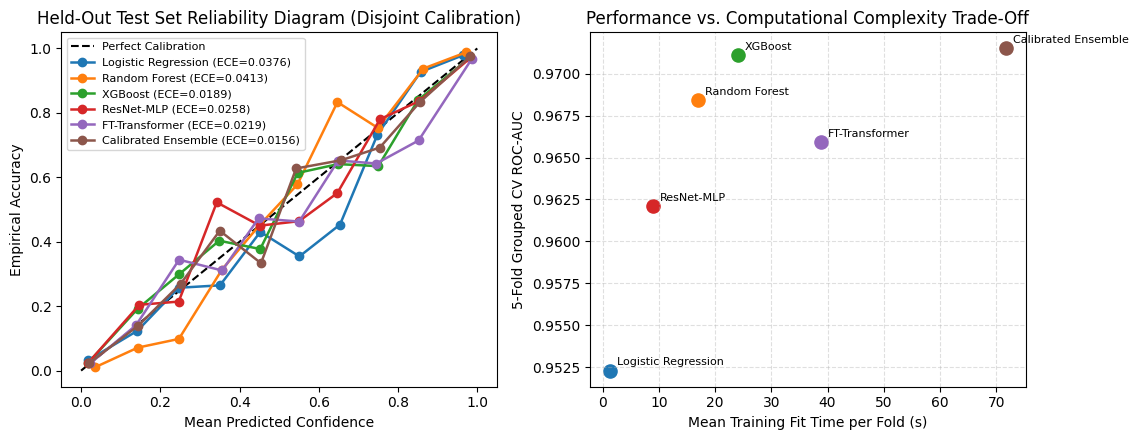

In [9]:
# Generate publication-grade figures for the Final Report & Poster
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.5))
plot_models = [
    (f"Logistic Regression (Tuned L2, C={best_C})", "Logistic Regression"),
    ("Random Forest (500 trees, depth=16)", "Random Forest"),
    (xgb_key, "XGBoost"),
    (rn_name, "ResNet-MLP"),
    (ft_name, "FT-Transformer"),
    (ens_name, "Calibrated Ensemble")
]
for key, short_label in plot_models:
    p = test_probs_dict[key]
    fpr, tpr, _ = roc_curve(y_test, p)
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[0].plot(fpr, tpr, lw=2, label=f"{short_label} (AUC={roc_auc_score(y_test, p):.4f})")
    axes[1].plot(rec, prec, lw=2, label=f"{short_label} (PR={average_precision_score(y_test, p):.4f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("Held-Out Test Set ROC Curves (m_test = 1,902)")
axes[0].legend(fontsize=8, loc="lower right")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Held-Out Test Set Precision-Recall Curves")
axes[1].legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.savefig("figures/fig1_roc_pr_curves.png", dpi=300)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.5))
axes[0].plot([0, 1], [0, 1], "k--", label="Perfect Calibration")
for key, short_label in plot_models:
    p = test_probs_dict[key]
    pt, pp = calibration_curve(y_test, p, n_bins=10)
    axes[0].plot(pp, pt, marker="o", lw=1.8, label=f"{short_label} (ECE={compute_ece(y_test, p):.4f})")
axes[0].set_xlabel("Mean Predicted Confidence")
axes[0].set_ylabel("Empirical Accuracy")
axes[0].set_title("Held-Out Test Set Reliability Diagram (Disjoint Calibration)")
axes[0].legend(fontsize=8, loc="upper left")
# Complexity vs Performance Pareto Plot
for rec_item in complexity_records:
    axes[1].scatter(rec_item["Mean Fit Time/Fold (s)"], rec_item["CV ROC-AUC"], s=90)
    axes[1].annotate(
        rec_item["Model"].split(" (")[0],
        (rec_item["Mean Fit Time/Fold (s)"], rec_item["CV ROC-AUC"]),
        textcoords="offset points", xytext=(5, 4), fontsize=8
    )
axes[1].set_xlabel("Mean Training Fit Time per Fold (s)")
axes[1].set_ylabel("5-Fold Grouped CV ROC-AUC")
axes[1].set_title("Performance vs. Computational Complexity Trade-Off")
axes[1].grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("figures/fig2_diagnostics_calibration.png", dpi=300)
print("Saved updated final figures: figures/fig1_roc_pr_curves.png and figures/fig2_diagnostics_calibration.png")